# P27 freeze: real-TESS validation manifest, loader, download plan

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-11-19_p27-freeze"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


## Load the frozen manifest and the MAST metadata plan

In [2]:
m = pd.read_csv(REPO / "datasets" / "tess_validation_v0.csv")
FIG = REPO / "reports" / "2026-11-19_p27-freeze" / "figures"; DATA = REPO / "reports" / "2026-11-19_p27-freeze" / "data"
FIG.mkdir(exist_ok=True)
plan_path = DATA / "plan_per_star.csv"   # per star: files and MB at MAST (dry-run metadata), written by the dry run summary
plan = pd.read_csv(plan_path) if plan_path.exists() else None
LAB = ["rotator", "contaminant_eb", "nonrotator", "nonrotator_candidate", "expected_undetectable"]
COL = dict(rotator="#1b6ca8", contaminant_eb="#c0572b", nonrotator="#6a8f3a", nonrotator_candidate="#8a6fb3", expected_undetectable="#999999")
print(m.label.value_counts().to_string())

label
rotator                  268
nonrotator               100
contaminant_eb            50
expected_undetectable     40
nonrotator_candidate      22


## Figure 1: final mix, class x period bin
Rotators and EBs have a truth period and so a period bin; the negative blocks have none and are shown as blocks (split by `source`). Nothing lies beyond 71 d (the 70-180 d block is skipped).

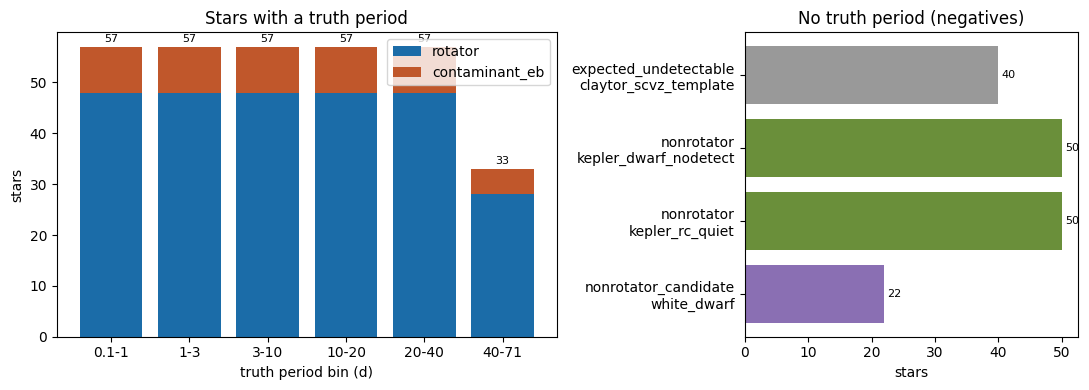

label        contaminant_eb  expected_undetectable  nonrotator  nonrotator_candidate  rotator
star_type                                                                                    
dwarf                    35                     40          49                     0      221
giant                     1                      0           0                     0        1
hot_star                 14                      0           1                     0       46
rc_giant                  0                      0          50                     0        0
white_dwarf               0                      0           0                    22        0


In [3]:
bins = ["0.1-1", "1-3", "3-10", "10-20", "20-40", "40-71"]
ct = pd.crosstab(m.pbin, m.label).reindex(bins).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[3, 2]))
b = np.zeros(len(bins))
for l in ["rotator", "contaminant_eb"]:
    ax[0].bar(bins, ct[l], bottom=b, color=COL[l], label=l); b += ct[l].values
for i, v in enumerate(b): ax[0].text(i, v + 1, int(v), ha="center", fontsize=8)
ax[0].set_xlabel("truth period bin (d)"); ax[0].set_ylabel("stars"); ax[0].legend(); ax[0].set_title("Stars with a truth period")
neg = m[m.truth_period.isna()].groupby(["label", "source"]).size().reset_index(name="n")
ax[1].barh([f"{a}\n{s}" for a, s in zip(neg.label, neg.source)], neg.n, color=[COL[l] for l in neg.label])
for i, v in enumerate(neg.n): ax[1].text(v + 0.5, i, v, va="center", fontsize=8)
ax[1].set_xlabel("stars"); ax[1].set_title("No truth period (negatives)"); ax[1].invert_yaxis()
fig.tight_layout(); fig.savefig(FIG / "mix_class_by_period.png", dpi=130); plt.show()
print(pd.crosstab(m.star_type, m.label).to_string())

## Figure 2: sector coverage per star
FFI sectors TESS observed the star (`n_sectors`, from TESSCut) against the TESS-SPOC / QLP files that exist at MAST. Few sectors mean long periods cannot be tested whatever the method.

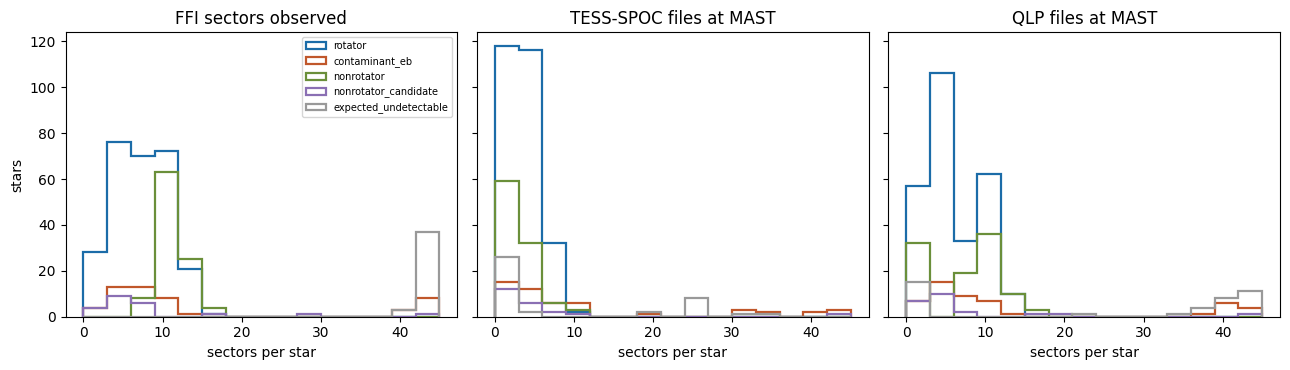

rotators with <=2 FFI sectors: 28 ; median FFI sectors: 6.0
                       n_sectors  n_tess_spoc  n_qlp
label                                               
contaminant_eb               7.0          5.0    6.5
expected_undetectable       44.0          0.0   37.5
nonrotator                  10.0          0.0    8.0
nonrotator_candidate         4.5          2.0    4.0
rotator                      6.0          3.0    4.0


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, (col, ttl) in zip(ax, [("n_sectors", "FFI sectors observed"), ("n_tess_spoc", "TESS-SPOC files at MAST"), ("n_qlp", "QLP files at MAST")]):
    for l in LAB:
        a.hist(m.loc[m.label == l, col], bins=np.arange(0, 47, 3), histtype="step", lw=1.6, color=COL[l], label=l)
    a.set_title(ttl); a.set_xlabel("sectors per star")
ax[0].set_ylabel("stars"); ax[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "sector_coverage.png", dpi=130); plt.show()
r = m[m.label == "rotator"]
print("rotators with <=2 FFI sectors:", int((r.n_sectors <= 2).sum()), "; median FFI sectors:", r.n_sectors.median())
print(m.groupby("label")[["n_sectors", "n_tess_spoc", "n_qlp"]].median().to_string())

## Figure 3: SPOC vs QLP availability
Per class, the share of stars whose best product is TESS-SPOC, QLP only (fallback) or nothing. `product_primary` comes from the manifest counts. Stars with `none` cannot be scored.

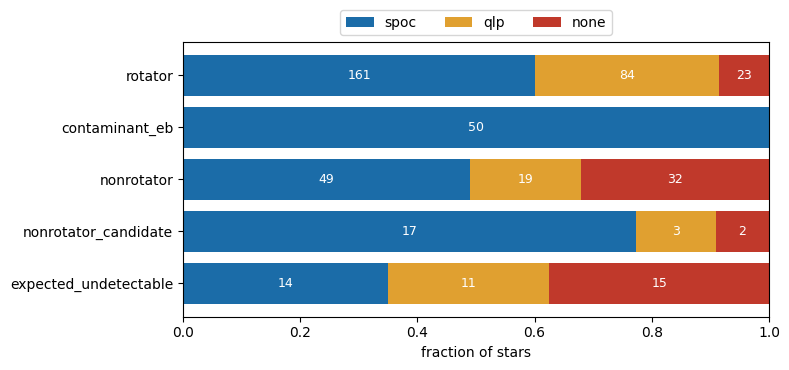

product_primary        spoc  qlp  none
label                                 
rotator                 161   84    23
contaminant_eb           50    0     0
nonrotator               49   19    32
nonrotator_candidate     17    3     2
expected_undetectable    14   11    15
scorable: 408 of 480


In [5]:
ct = pd.crosstab(m.label, m.product_primary).reindex(LAB)[["spoc", "qlp", "none"]]
frac = ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(LAB))
for c, colr in zip(["spoc", "qlp", "none"], ["#1b6ca8", "#e0a030", "#c0392b"]):
    ax.barh(LAB, frac[c], left=left, color=colr, label=c)
    for i, (v, lft) in enumerate(zip(frac[c], left)):
        if v > 0.06: ax.text(lft + v / 2, i, f"{int(ct[c].iloc[i])}", ha="center", va="center", color="w", fontsize=9)
    left += frac[c].values
ax.set_xlabel("fraction of stars"); ax.invert_yaxis(); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); fig.savefig(FIG / "spoc_vs_qlp_availability.png", dpi=130); plt.show()
print(ct.to_string()); print("scorable:", int(m.scorable.sum()), "of", len(m))

## Download size from the MAST metadata dry run (if `data/plan_per_star.csv` exists)

In [6]:
if plan is not None:
    print(plan.groupby("product")[["n_files", "mb"]].sum().round(1).to_string())
    print("total GB:", round(plan.mb.sum() / 1e3, 2), "files:", int(plan.n_files.sum()))
else:
    print("no plan table saved")

         n_files      mb
product                 
qlp         1286   524.9
spoc        1915  1165.8
total GB: 1.69 files: 3201
